# 6. Data quality, mode table and replication with another session

1. **Quality of each strike:** clipping, signal-to-noise ratio, another peak within the 0.4 s window, peak level (iOS
   limiter) and accelerometer pulse. It is checked that the results do not depend on the strikes with unfavourable
   indicators, and the **final strike table** `data/derived/strikes.csv` is written.
2. **Mode table**: the 13 global modes with their frequency, spread between strikes, zones where they appear and
   damping (from the tables of notebook 03).
3. **Replication with another session and other equipment**: the 52 phyphox records of **7 February 2025**, recorded
   with another app and struck with **a stone from the surroundings**, against the main session of **19 October
   2025**, recorded with Voice Record Pro and a **rubber-covered hammer**. The striker changes which modes are excited
   and how strongly (the harder stone excites high frequencies more), but it should not change the **frequencies** of
   the modes, which are properties of the stone. The replication therefore compares only frequencies, not timbre.
4. **256 Hz tuning fork** (25 November 2025): first check of the frequency scale.

**Inputs:** WAV files of 19 Oct 2025, `intermediate/strikes_with_acceleration.csv` (02), `intermediate/features.csv`
(01), `tables/t03_damping_strikes.csv` and `t03_damping_modes.csv` (03), phyphox zip files of 7 Feb 2025, tuning-fork
WAV files. **Outputs:** `data/derived/strikes.csv`, `tables/t06_strike_quality.csv`, `tables/t06_mode_table.csv`,
`tables/t06_replication.csv`, `tables/t06_tuning_fork.csv`, `figures/fig06a_replication.png`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

import glob, io, zipfile, datetime as dt
from scipy import signal, stats
from scipy.io import wavfile
warnings.filterwarnings("ignore", category=wavfile.WavFileWarning)
CAT = pd.read_csv(C.TABLES / "t03_mode_catalogue.csv").mode_Hz.tolist()   # catalogue of notebook 03 (13 modes)
TZ = dt.timezone(dt.timedelta(hours=-5))
def t_wav(n):   # start time of the WAV file from its name
    return dt.datetime(2025, 10, 19, int(n[9:11]), int(n[11:13]), int(n[13:15]), tzinfo=TZ).timestamp()

## 6.1 Quality control of each strike

For each strike its peak is located in the WAV file (absolute time from notebook 02) and the following is measured:

- **Clipping:** any sample of either channel at ≥ 99 % of the 16-bit maximum in the window.
- **Signal-to-noise ratio (dB):** RMS of the filtered 0.4 s window (> 300 Hz) against the background noise of the
  recording (10th percentile of the RMS in 100 ms frames).
- **Previous resonance (dB):** RMS of the 0.3 s before the strike relative to that of the window. The modes ring for
  2–3 s and strikes follow each other about every 1.2 s, so the window also contains the tail of the previous strike;
  values above −10 dB indicate that this tail is important.
- **Next peak within the window:** a new peak (detected in the band > 4 kHz with the criteria of notebook 01: median +
  40 MAD, prominence 20 MAD, peaks ≥ 0.15 s apart) between 30 ms and 0.4 s after the peak, which would contaminate the
  spectrum.

In [2]:
g = pd.read_csv(C.INTERMEDIATE / "strikes_with_acceleration.csv")
bh, ah = signal.butter(C.FILTER_ORDER, C.HIGHPASS_HZ / (0.5 * C.FS), btype="high")
b4, a4 = signal.butter(4, 4000 / (0.5 * C.FS), btype="high")
rows = []
for w, gw in g.groupby("file"):
    _, x = wavfile.read(C.AUDIO / w)
    xf = signal.filtfilt(bh, ah, x.astype(np.float32).mean(axis=1))
    frames = xf[: len(xf) // 4800 * 4800].reshape(-1, 4800); noise = np.percentile(np.sqrt((frames ** 2).mean(axis=1)), 10)
    y4 = signal.filtfilt(b4, a4, x.astype(np.float32).mean(axis=1)); k = int(0.002 * C.FS)
    env = np.convolve(np.abs(y4), np.ones(k) / k, "same"); base = np.median(env); mad = np.median(np.abs(env - base))
    ons, _ = signal.find_peaks(env, height=base + 40 * mad, prominence=20 * mad, distance=int(0.15 * C.FS))   # same criteria as notebook 01
    for r in gw.itertuples():
        i = int(round((r.t_abs - t_wav(w)) * C.FS)); i0 = i - int(C.PRE_PEAK * C.FS); i1 = i0 + C.STRIKE_SAMPLES
        clipped = np.abs(x[i0:i1]).max() >= 0.99 * 32767
        rms = np.sqrt(np.mean(xf[i0:i1] ** 2)); snr = 20 * np.log10(rms / noise)
        prev = 20 * np.log10(np.sqrt(np.mean(xf[max(0, i0 - int(0.3 * C.FS)):i0] ** 2)) / rms)
        nxt = bool(((ons > i + int(0.03 * C.FS)) & (ons < i1)).any())
        peak = np.abs(x[i - 2400:i + 2400, 0]).max() / 32768
        rows.append({"zone": r.zone, "strike": r.strike, "file": w, "clipped": clipped, "snr_dB": snr, "prev_resonance_dB": prev,
                     "other_peak_in_window": nxt, "audio_peak_fs": peak, "limiter": peak >= 0.90})
q = pd.DataFrame(rows)
q["doubtful"] = q.clipped | (q.snr_dB < 10) | (q.prev_resonance_dB > -10) | q.other_peak_in_window
q.to_csv(C.TABLES / "t06_strike_quality.csv", index=False)
print(f"{len(q)} strikes | clipped: {q.clipped.sum()} | SNR < 10 dB: {(q.snr_dB < 10).sum()} | "
      f"previous resonance > −10 dB: {(q.prev_resonance_dB > -10).sum()} | "
      f"other peak within the window: {q.other_peak_in_window.sum()} | with some unfavourable indicator: {q.doubtful.sum()}")
print(f"Previous resonance: median {q.prev_resonance_dB.median():.1f} dB")
print(f"SNR: median {q.snr_dB.median():.1f} dB (5th percentile = {q.snr_dB.quantile(.05):.1f} dB, minimum {q.snr_dB.min():.1f} dB)")
print(f"Audio peak ≥ 0.90 of full scale (iOS limiter): {q.limiter.sum()} ({q.limiter.mean():.0%})")

613 strikes | clipped: 0 | SNR < 10 dB: 0 | previous resonance > −10 dB: 268 | other peak within the window: 22 | with some unfavourable indicator: 279
Previous resonance: median -11.7 dB
SNR: median 21.4 dB (5th percentile = 16.9 dB, minimum 14.4 dB)
Audio peak ≥ 0.90 of full scale (iOS limiter): 534 (87%)


**Do the results change without the strikes with an unfavourable indicator?** Two central calculations are repeated
with the strikes of the characterisation set: the zone means of the centroid and of the bandwidth (notebook 01) and the
effect size of the zone in the Kruskal–Wallis test (notebook 05).

In [3]:
f = pd.read_csv(C.INTERMEDIATE / "features.csv")
f = f[f.set == "characterisation"]   # characterisation set, as in notebook 05
f = f.merge(q[["zone", "strike", "doubtful"]], on=["zone", "strike"], how="left")
res = []
for c in ["spectral_centroid", "spectral_bandwidth", "mfcc_0", "mfcc_1"]:
    all_ = f.groupby("zone")[c].mean(); clean = f[f.doubtful != True].groupby("zone")[c].mean()
    def eps2(d):
        H = stats.kruskal(*[v[c].values for _, v in d.groupby("zone")]).statistic
        return (H - d.zone.nunique() + 1) / (len(d) - d.zone.nunique())
    res.append({"feature": c, "r_zone_means": all_.corr(clean.reindex(all_.index)),   # zones with clean strikes
                "zones_with_clean_strikes": len(clean),
                "epsilon2_all": eps2(f), "epsilon2_without_doubtful": eps2(f[f.doubtful != True]),
                "strikes_without_doubtful": int((f.doubtful != True).sum())})
sens = pd.DataFrame(res); sens.round(3)

,feature,r_zone_means,zones_with_clean_strikes,epsilon2_all,epsilon2_without_doubtful,strikes_without_doubtful
0,spectral_centroid,0.84,24,0.37,0.62,180
1,spectral_bandwidth,0.93,24,0.58,0.76,180
2,mfcc_0,0.97,24,0.53,0.74,180
3,mfcc_1,0.89,24,0.35,0.57,180


### Final strike table

One row per strike with its location, its set, its quality indicators, the acceleration of the strike and its 15
spectral features. This is the data set used in the article (`data/derived/strikes.csv`; columns in
`data/data_dictionary.csv`).

In [4]:
gb = pd.read_csv(C.INTERMEDIATE / "strikes.csv")
fa = pd.read_csv(C.INTERMEDIATE / "features.csv").drop(columns=["file", "t_s", "set"])
tab = (gb.merge(q.drop(columns=["file", "doubtful"]), on=["zone", "strike"])
         .merge(g[["zone", "strike", "acc_peak", "acc_snr"]], on=["zone", "strike"])
         .merge(fa, on=["zone", "strike"]))
tab["acc_recorded"] = tab.acc_peak.notna(); tab["acc_clear_pulse"] = tab.acc_snr > 8
tab = tab.rename(columns={"amp_rel": "peak_amp_rel", "acc_peak": "acc_peak_ms2"})
order = ["zone", "strike", "file", "run", "set", "t_s", "i_peak", "peak_amp_rel", "modes_present", "clipped", "snr_dB",
         "prev_resonance_dB", "other_peak_in_window", "audio_peak_fs", "limiter", "acc_recorded", "acc_peak_ms2", "acc_snr",
         "acc_clear_pulse"] + C.RF_FEATURES
tab = tab[order].sort_values(["zone", "strike"])
C.STRIKES.parent.mkdir(exist_ok=True)
tab.round(6).to_csv(C.STRIKES, index=False)
print(f"{len(tab)} strikes, {tab.file.nunique()} recordings, {tab.zone.nunique()} zones → {C.STRIKES.relative_to(C.ROOT)}")
print(f"with accelerometer data: {tab.acc_recorded.sum()} | with a clear pulse: {tab.acc_clear_pulse.sum()}")
print(tab.groupby("set").agg(recordings=("file", "nunique"), strikes=("zone", "size"), zones=("zone", "nunique")))

613 strikes, 18 recordings, 24 zones → data/derived/strikes.csv
with accelerometer data: 486 | with a clear pulse: 454
                  recordings  strikes  zones
set                                         
characterisation          11      371     24
validation                 7      242     24


## 6.2 Mode table

Mean frequency and standard deviation between strikes of each mode (long windows of notebook 03, valid fits only),
number of strikes and zones where the mode is measured, and damping: median Q with its interquartile range, T60 and
η = 1/Q.

In [5]:
dg = pd.read_csv(C.TABLES / "t03_damping_strikes.csv"); dg = dg[dg.valid]
dm = pd.read_csv(C.TABLES / "t03_damping_modes.csv").set_index("mode")
tm = dg.groupby("mode").agg(f_mean_Hz=("f", "mean"), f_sd_Hz=("f", "std"), strikes=("f", "size"), zones=("zone", "nunique")).reset_index()
tm["Q_median"] = tm["mode"].map(dm.Q); tm["Q_p25"] = tm["mode"].map(dm.Q_p25); tm["Q_p75"] = tm["mode"].map(dm.Q_p75)
tm["T60_s"] = tm["mode"].map(dm.T60_s); tm["eta_x1000"] = 1000 / tm.Q_median
tm["f_relative"] = tm.f_mean_Hz / tm.f_mean_Hz.iloc[0]
tm.to_csv(C.TABLES / "t06_mode_table.csv", index=False)
tm.round({"f_mean_Hz": 2, "f_sd_Hz": 2, "Q_median": 0, "Q_p25": 0, "Q_p75": 0, "T60_s": 2, "eta_x1000": 2, "f_relative": 3})

,mode,f_mean_Hz,f_sd_Hz,strikes,zones,Q_median,Q_p25,Q_p75,T60_s,eta_x1000,f_relative
0,384.9,384.85,0.13,65,12,378.0,359.0,410.0,2.16,2.64,1.00
1,599.5,599.42,0.17,98,14,555.0,533.0,598.0,2.03,1.80,1.56
2,759.2,759.16,0.06,66,15,1038.0,985.0,1103.0,3.01,0.96,1.97
3,848.9,848.80,0.10,98,17,1047.0,1010.0,1082.0,2.71,0.96,2.21
4,969.5,969.51,0.16,163,15,729.0,694.0,785.0,1.65,1.37,2.52
5,1259.9,1259.98,0.15,59,8,1077.0,1033.0,1182.0,1.88,0.93,3.27
6,1298.6,1298.78,0.48,50,5,598.0,552.0,643.0,1.01,1.67,3.38
7,1348.8,1348.77,0.08,147,15,1186.0,1134.0,1256.0,1.93,0.84,3.50
8,1389.2,1389.23,0.03,47,7,1237.0,1204.0,1319.0,1.96,0.81,3.61
9,1645.2,1645.25,0.14,122,15,1044.0,999.0,1136.0,1.40,0.96,4.28


## 6.3 Replication with the session of 7 February 2025 (phyphox, stone striker)

Each phyphox record keeps only 0.5 s (2 Hz resolution). To estimate the frequency of each peak with sub-Hz precision
the signal is zero-padded, a Hann window is used and the maximum is interpolated with a parabola on a logarithmic
scale. Peaks between 300 and 2500 Hz with at least 8 % of the maximum amplitude are searched for and assigned to the
nearest October mode if they are less than 8 Hz away.

In [6]:
rows = []
for fz in sorted(glob.glob(str(C.REPLICATION / "S1_Z*.zip"))):
    a = pd.read_csv(io.BytesIO(zipfile.ZipFile(fz).read("Audio data.csv"))).iloc[:, 1].to_numpy()
    a = a - a.mean(); N = C.FS * 4
    X = np.abs(np.fft.rfft(a * np.hanning(len(a)), N)); fr = np.fft.rfftfreq(N, 1 / C.FS)
    Xm = np.where((fr > C.HIGHPASS_HZ) & (fr < 2500), X, 0); Xm = Xm / Xm.max()
    p, _ = signal.find_peaks(Xm, height=0.08, distance=int(15 / fr[1]))
    for i in p:
        y0, y1, y2 = np.log(X[i - 1:i + 2]); fp = (i + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)) * fr[1]
        j = int(np.argmin(np.abs(np.array(CAT) - fp)))
        rows.append({"record": Path(fz).stem, "f_Hz": fp, "amp_rel": Xm[i], "mode": CAT[j], "diff_Hz": fp - CAT[j]})
pk = pd.DataFrame(rows); near = pk[pk.diff_Hz.abs() < 8]
print(f"{pk.record.nunique()} records, {len(pk)} peaks; {len(near)} less than 8 Hz from an October mode")
oct_ = tm.set_index("mode")
rep = near.groupby("mode").agg(records=("record", "nunique"), f_feb_Hz=("f_Hz", "median"), sd_feb_Hz=("f_Hz", "std")).reset_index()
rep["f_oct_Hz"] = rep["mode"].map(oct_.f_mean_Hz)
rep["diff_Hz"] = rep.f_feb_Hz - rep.f_oct_Hz; rep["diff_pct"] = 100 * rep.diff_Hz / rep.f_oct_Hz
rep["records_pct"] = 100 * rep.records / pk.record.nunique()
rep.to_csv(C.TABLES / "t06_replication.csv", index=False)
p_sign = stats.binomtest(int((rep.diff_pct < 0).sum()), len(rep), 0.5).pvalue
print(f"Difference February − October: median {rep.diff_pct.median():+.2f} % (range {rep.diff_pct.min():+.2f} to {rep.diff_pct.max():+.2f} %); "
      f"lower in {(rep.diff_pct < 0).sum()} of {len(rep)} modes (sign test p = {p_sign:.4f})")
rep.round(2)

52 records, 998 peaks; 504 less than 8 Hz from an October mode
Difference February − October: median -0.09 % (range -0.35 to -0.07 %); lower in 13 of 13 modes (sign test p = 0.0002)


,mode,records,f_feb_Hz,sd_feb_Hz,f_oct_Hz,diff_Hz,diff_pct,records_pct
0,384.9,45,383.87,0.51,384.85,-0.99,-0.26,86.54
1,599.5,42,597.50,1.45,599.42,-1.93,-0.32,80.77
2,759.2,45,758.45,0.58,759.16,-0.71,-0.09,86.54
3,848.9,44,848.09,0.42,848.80,-0.71,-0.08,84.62
4,969.5,38,967.57,1.05,969.51,-1.95,-0.20,73.08
5,1259.9,36,1258.51,1.07,1259.98,-1.47,-0.12,69.23
6,1298.6,27,1294.26,3.00,1298.78,-4.52,-0.35,51.92
7,1348.8,40,1347.79,1.12,1348.77,-0.98,-0.07,76.92
8,1389.2,30,1388.24,0.90,1389.23,-0.98,-0.07,57.69
9,1645.2,44,1643.76,1.93,1645.25,-1.49,-0.09,84.62


Strong peaks (> 30 %) away from the 13 modes: 52, of which 20 in zone 2 of February
Recurrent peak near 1765 Hz: 4 records, median 1765.4 Hz


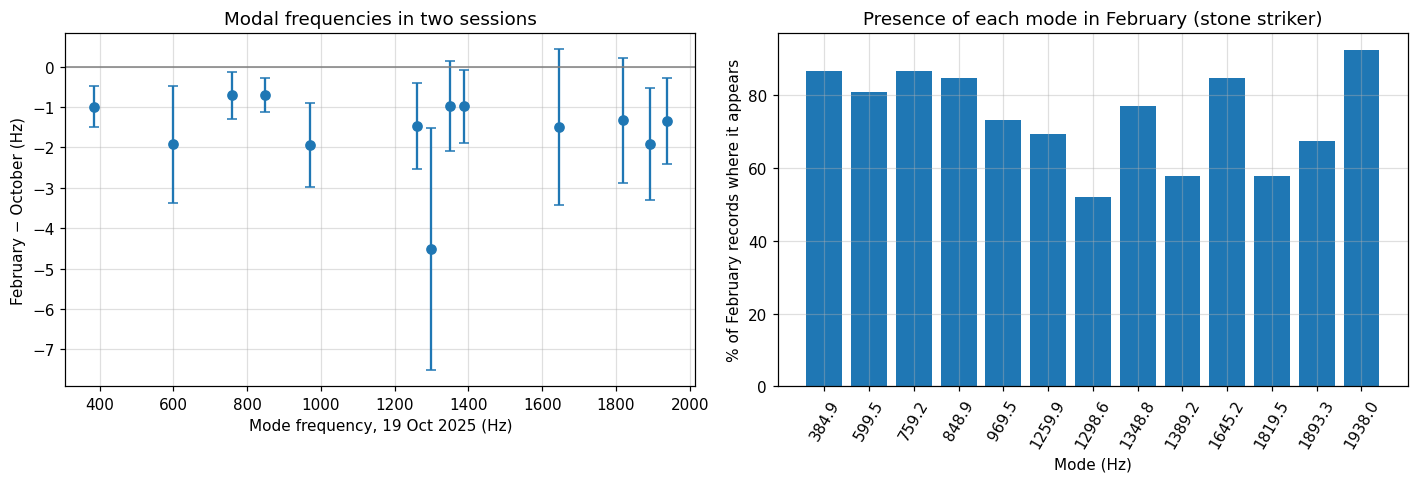

In [7]:
others = pk[(pk.diff_Hz.abs() >= 8) & (pk.amp_rel > 0.3)]
near_1765 = others[(others.f_Hz > 1755) & (others.f_Hz < 1775)]
print(f"Strong peaks (> 30 %) away from the {len(CAT)} modes: {len(others)}, of which {others.record.str.contains('Z02').sum()} in zone 2 of February")
print(f"Recurrent peak near 1765 Hz: {len(near_1765)} records, median {near_1765.f_Hz.median():.1f} Hz")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].errorbar(rep.f_oct_Hz, rep.f_feb_Hz - rep.f_oct_Hz, yerr=rep.sd_feb_Hz, fmt="o", color="C0", capsize=3)
ax[0].axhline(0, color="0.5", lw=1); ax[0].set_xlabel("Mode frequency, 19 Oct 2025 (Hz)")
ax[0].set_ylabel("February − October (Hz)"); ax[0].set_title("Modal frequencies in two sessions")
ax[1].bar(rep["mode"].astype(str), rep.records_pct, color="C0")
ax[1].set_xlabel("Mode (Hz)"); ax[1].set_ylabel("% of February records where it appears")
ax[1].set_title("Presence of each mode in February (stone striker)"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(C.FIGURES / "fig06a_replication.png", dpi=150, bbox_inches="tight"); plt.show()

## 6.4 256 Hz tuning fork (25 November 2025)

Peak frequency (interpolated) of each take of the 256 Hz tuning fork with a printed frequency. The complete check of
the instrument (256 and 329.6 Hz tuning forks and steel bowl, 28 October 2026) is in notebook 09.

In [8]:
rows = []
for fw in sorted(glob.glob(str(C.TUNING_FORK / "*.wav"))):
    fs, s = wavfile.read(fw); s = s.astype(float) - s.mean(); N = max(len(s), fs * 20)
    X = np.abs(np.fft.rfft(s * np.hanning(len(s)), N)); fr = np.fft.rfftfreq(N, 1 / fs); X[(fr < 150) | (fr > 3000)] = 0
    i = int(np.argmax(X)); y0, y1, y2 = np.log(X[i - 1:i + 2]); f0 = (i + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)) * fr[1]
    rows.append({"file": Path(fw).name, "f_measured_Hz": f0, "duration_s": len(s) / fs})
dp = pd.DataFrame(rows)
dp.to_csv(C.TABLES / "t06_tuning_fork.csv", index=False)
print(f"{len(dp)} takes: {dp.f_measured_Hz.mean():.2f} ± {dp.f_measured_Hz.std():.2f} Hz (nominal 256 Hz, "
      f"error {100 * (dp.f_measured_Hz.mean() / 256 - 1):+.2f} %)")

5 takes: 256.43 ± 0.02 Hz (nominal 256 Hz, error +0.17 %)


## 6.5 Conclusion

- **Quality:** no strike has clipped samples and all exceed the background noise of their recording by more than
  10 dB. In part of the strikes the tail of the previous strike is important; repeating the calculations without them
  does not change the conclusions (sensitivity table). Most strikes reach the iOS peak limiter during their first
  milliseconds (notebook 09).
- **Modes:** the frequencies are very stable within the main session (standard deviation between strikes of 0.03 to
  0.48 Hz). Their ratios to the lowest mode, 384.9 Hz (1 : 1.56 : 1.97 : 2.21 : 2.52 …), do not follow a harmonic
  series, as is typical of an irregular plate.
- **Replication:** the 13 modes reappear in February, eight months earlier, with another app (phyphox) and another
  striker (a stone), in 52–92 % of the records. All 13 February frequencies are lower than in October (median
  −0.09 %, range −0.35 to −0.07 %; sign test p ≈ 0.0002), which is consistent with a change of the elastic modulus of
  the rock (temperature or moisture), not measured.
- In February there are also strong peaks outside the catalogue and a recurrent peak near 1765 Hz, to be expected with
  a hard striker.